# Training & Evaluation — Control (α = 0) vs Constrained (α = 1)

Trains both networks over several seeds, then evaluates them:

1. **Predictions + labels** — `predictions (N, T, 2)`, `labels (N,)`
2. **2D trajectories & Hidden activations**
3. **Heatmaps** of the condition-averaged, peak-sorted activity
4. **RSM** matrices & plots, control and constrained
5. **Boxplot — Epochs**
6. **Boxplot — Correlation**


### Paths

In [ ]:
##### paths: make src/ importable, and name the data / results folders
import sys, pathlib

ROOT    = pathlib.Path.cwd().parent
SRC     = ROOT / "src"
DATA    = ROOT / "data"
RESULTS = ROOT / "results"
sys.path.insert(0, str(SRC))

print("src     :", SRC)
print("data    :", DATA)
print("results :", RESULTS)

## **Configuration**

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.stats import ttest_rel
from pathlib import Path
import sys
sys.path.append("../src")

from config import *        # constants + KWARGS_DATA / KWARGS_MODEL / KWARGS_LOAD_AND_PREDICT
from utils import *         # CustomReLU, CustomMSE, make_dataset
from data import *          # generate_diverging_trajectories
from model import *         # Model_1
from loading import *       # KWARGS_MODEL_PATH, model_path, load_and_predict
from analysis import *      # compute_rsm
from plotting import *      # plot_trajectories_2d, plot_sorted_averaged_activations,
                            # plot_rsm, boxplot_with_lines, plot_siginficance_symbol_paired

print_config(settings())
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791366846.862901  157766 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791366846.891976  157766 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791366847.904460  157766 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


task:
      K: 5
      angle_deg: 20
      num_steps: 132
      n_hold_origin: 16
      n_movement: 100
      n_hold_target: 16
      n_trials: 40960
      augmentation_factor: 13
      noise_level: 0.05
      sigma: 2

model:
      hidden_units: 200
      connectivity_rate: 0.4
      n_active_connections: 16000
      d_in: 263
      d_out: 2
      noise_amp: 0.1
      init_scale: 0
      mixing: (1, 1, 1)

training:
      learning_rate: 0.0002
      batch_size: 2000
      reg: (0.05, 0.005, 0.05)
      grad_clip_norm: 1.0
      loss_threshold: 0.06
      max_epochs: 200000
      num_runs: 20


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1791366849.136877  157766 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


### Run-level knobs

In [3]:
N_RUNS    = 1     # NUM_RUNS
MAX_STEPS = MAX_TRAINING_TRIALS
AUGMENT   = AUGMENTATION_FACTOR
BATCH     = BATCH_SIZE
COLORS    = ["#c8712d", "#d9a46a", "#a8a8a8", "#7597b5", "#2e5f8a"]
ALPHAS_USED = (0, 1)

sys.path.append("..")
MODELS_DIR = Path(RESULTS) / "models"
CKPT_DIR   = Path(RESULTS) / "ckpts"
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"{N_RUNS} runs x 2 networks | <= {MAX_STEPS} steps | batch {BATCH} | "
      f"K = {NUM_TRAJECTORIES} | T = {NUM_STEPS} | alpha_constrained = 1 x {FACTOR:g}")

1 runs x 2 networks | <= 200000 steps | batch 2000 | K = 5 | T = 132 | alpha_constrained = 1 x 10


## **Data**

INPUTS : (40960, 1) | OUTPUTS : (40960, 132, 2)
train  : (38960, 1) (38960, 132, 2)
eval   : (2000, 1) (2000, 132, 2)
conditions : [0. 1. 2. 3. 4.]


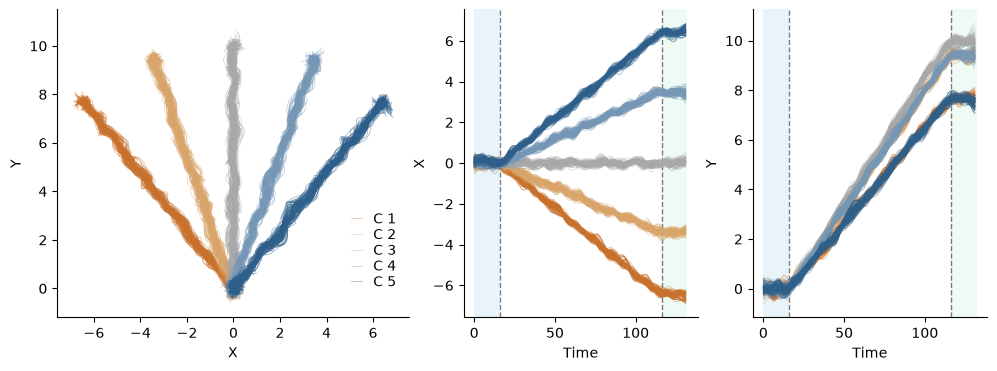

In [4]:
KWARGS_DATA["plot"] = False
KWARGS_DATA["augmentation_factor"] = AUGMENT

INPUTS, OUTPUTS, angles = generate_diverging_trajectories(**KWARGS_DATA)

##### held-out evaluation batch, train on the rest  (as in Training.txt)
I_val, O_val = INPUTS[:BATCH], OUTPUTS[:BATCH]
I_train, O_train = INPUTS[BATCH:], OUTPUTS[BATCH:]

print("INPUTS :", INPUTS.shape, "| OUTPUTS :", OUTPUTS.shape)
print("train  :", I_train.shape, O_train.shape)
print("eval   :", I_val.shape, O_val.shape)
print("conditions :", np.unique(I_val))


outputs, inputs= OUTPUTS[:500], INPUTS[:500]
fig, axes= plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1, 1], "wspace": 0.2})
ax=axes[0]
plot_trajectories_2d(ax, outputs, inputs, legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)})
ax.set_aspect('auto')
ax.set_ylim(-1.2, 11.5)
ax.set_yticks([0, 2, 4, 6, 8, 10])
ax=axes[1]
plot_X_evolution(ax, outputs, inputs, n_hold_origin=KWARGS_DATA["n_hold_origin"], 
                 n_hold_target=KWARGS_DATA["n_hold_target"], use_legend=False)
ax=axes[2]
plot_Y_evolution(ax, outputs, inputs,
                 n_hold_origin=KWARGS_DATA["n_hold_origin"], n_hold_target=KWARGS_DATA["n_hold_target"],
                 use_legend=False, legend_kwargs={"loc": "upper left", "bbox_to_anchor": (-0.01, 1.)})
plt.show()

## **Training**

Both networks of a run share the seed, so they share the connectivity mask and the
initial weights and differ only in the correlation penalty. Per run and per model we
keep **Epochs** (`len(lc[0])`, the number of optimisation steps, as in `Training.txt`)
and **Correlation** (`model.tf_corr_penalty` on the held-out batch).

In [6]:
EPOCHS = {name: [] for name in MODEL_LABELS}
CORRS  = {name: [] for name in MODEL_LABELS}
PATHS  = {name: [] for name in MODEL_LABELS}
LOSSES = {name: [] for name in MODEL_LABELS}

for run in range(1, N_RUNS + 1):
    for name, alpha in zip(MODEL_LABELS, ALPHAS_USED):

        tf.keras.utils.set_random_seed(RANDOM_SEED + run)

        ##### build
        model = Model_1(**{**KWARGS_MODEL,
                           "alpha": alpha,
                           "num_steps": OUTPUTS.shape[1],
                           "batch_size": BATCH,
                           "seed": RANDOM_SEED + run})
        model.build(input_shape=(None, 1))

        print("-" * 62)
        print(f"  run {run}/{N_RUNS}  |  {name}  |  alpha = {float(model.alpha.numpy()):.3f}")
        print("-" * 62)

        ##### train
        lc, lc_val, n_steps, losses_log, losses_val_log = model.train(
            INPUTS=I_train, OUTPUTS=O_train,
            INPUTS_val=I_val, OUTPUTS_val=O_val,
            correlation_penalty=True,
            behavioral_loss_threshold=BEHAVIORAL_LOSS_THRESHOLD,
            MAX_TRAINING_TRIALS=MAX_STEPS,
            LOG_EVERY=LOG_EVERY,
            CKPT_EVERY=10 ** 9,
            ckpt_dir=f"{CKPT_DIR}/run_{run}_alpha_{alpha}",
            save_name=f"Penalized_run_{run}_alpha_{alpha}",
        )

        ##### save the weights under the project's naming convention
        MODEL_PATH = model_path(**{**KWARGS_MODEL_PATH,
                                   "K": NUM_TRAJECTORIES, "angle": ANGLE,
                                   "run": run, "alpha": alpha,
                                   "models_dir": MODELS_DIR})
        model.save_weights(MODEL_PATH)

        ##### metrics of this run
        I_t = tf.cast(I_val, model.data_dtype)
        preds, hidden_s = model(I_t)

        EPOCHS[name].append(len(lc[0]))
        CORRS[name].append(float(model.tf_corr_penalty(I_t, hidden_s).numpy()))
        LOSSES[name].append(np.asarray(lc[0], dtype=float))
        PATHS[name].append(MODEL_PATH)

        print(f"  epochs = {EPOCHS[name][-1]}  |  correlation = {CORRS[name][-1]:.4f}")
        print(f"  saved  : {MODEL_PATH}\n")

        del model, preds, hidden_s

print("Epochs      :", EPOCHS)
print("Correlation :", CORRS)

--------------------------------------------------------------
  run 1/1  |  Control  |  alpha = 0.000
--------------------------------------------------------------
----------------------------
epoch=    50/200000 | alpha=0.000 |  
TRAINING   :  total loss =0.3090 | behavioral loss=0.1449 |  pen loss=7.3141 |  
VALIDATION :  total loss =0.3598 | behavioral loss=0.1902 |  pen loss=7.4070 |  
----------------------------
epoch=   100/200000 | alpha=0.000 |  
TRAINING   :  total loss =0.2116 | behavioral loss=0.0815 |  pen loss=7.3976 |  
VALIDATION :  total loss =0.1999 | behavioral loss=0.0715 |  pen loss=7.3357 |  

------------------------ Training finished ------------------------
  Epochs           : 119 / 200000
  Best MSE         : 0.063938
  Best MSE val     : 0.058746
  Final Corr       : 7.447825
  Final Corr val   : 7.505100
  MSE Threshold    : 0.06
  Hidden Units     : 200
  Time Steps       : 132
  Connectivity     : 0.4
  Learning Rate    : 0.0002
  Batch Size       : 200

## **1. Predictions with their labels & Hidden activations**

Both networks of run 1 are re-loaded from disk with `load_and_predict` and run on the
held-out batch.

* `PREDICTIONS[name]` → `(N, T, 2)`
* `LABELS` → `(N,)`
* `HIDDEN[name]` → `(N, N_units, T)`

In [7]:
RUN_SHOWN = 1

PREDICTIONS = {}
HIDDEN      = {}
MODELS      = {}

LABELS = I_val.reshape(-1)                      # (N,)

for name, alpha in zip(MODEL_LABELS, ALPHAS_USED):

    preds, hidden_s, model = load_and_predict(**{**KWARGS_LOAD_AND_PREDICT,
                                                 "I": I_val,
                                                 "K": NUM_TRAJECTORIES,
                                                 "num_steps": OUTPUTS.shape[1],
                                                 "batch_size": BATCH,
                                                 "alpha": alpha * FACTOR,
                                                 "model_name": PATHS[name][RUN_SHOWN - 1]})

    PREDICTIONS[name] = preds.numpy()                                 # (N, T, 2)
    HIDDEN[name]      = np.transpose(hidden_s.numpy(), (0, 2, 1))     # (N, N_units, T)
    MODELS[name]      = model

    print(f"{name:12s} | predictions {PREDICTIONS[name].shape} | "
          f"hidden {HIDDEN[name].shape}")

print(f"{'labels':12s} | {LABELS.shape} | values {np.unique(LABELS)}")

Control      | predictions (2000, 132, 2) | hidden (2000, 200, 132)
Constrained  | predictions (2000, 132, 2) | hidden (2000, 200, 132)
labels       | (2000,) | values [0. 1. 2. 3. 4.]


## **2. 2D trajectories of the predictions**

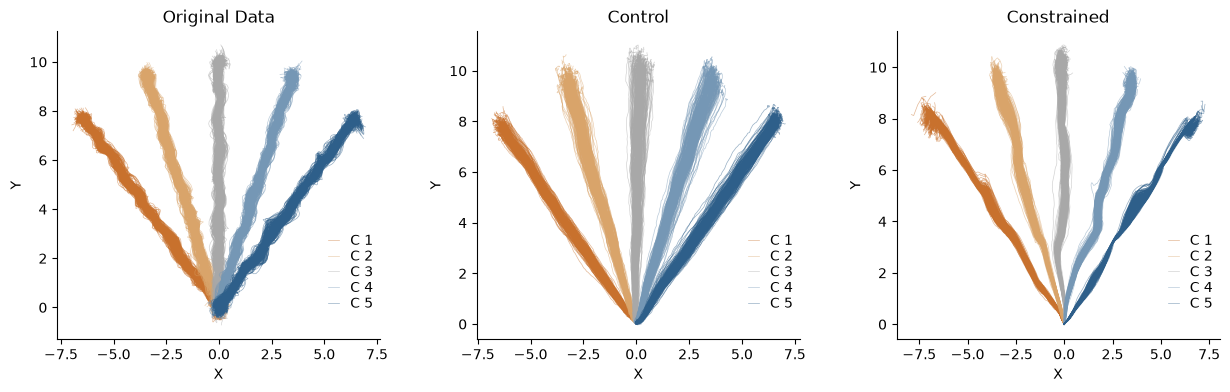

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.subplots_adjust(wspace=0.3)

plot_trajectories_2d(axes[0], O_val, I_val, title="Original Data",
                     legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)})

plot_trajectories_2d(axes[1], PREDICTIONS[MODEL_LABELS[0]], I_val, title=MODEL_LABELS[0],
                     legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)})

plot_trajectories_2d(axes[2], PREDICTIONS[MODEL_LABELS[1]], I_val, title=MODEL_LABELS[1],
                     legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)})

plt.show()

## **3. Heatmaps**

`plot_sorted_averaged_activations` averages within condition, normalises each unit and
sorts the units once by their peak time in condition 1, then reuses that order for every
condition. It returns the sorted, condition-averaged activity `(K, N_units, T)`, which
the RSM below is computed from.

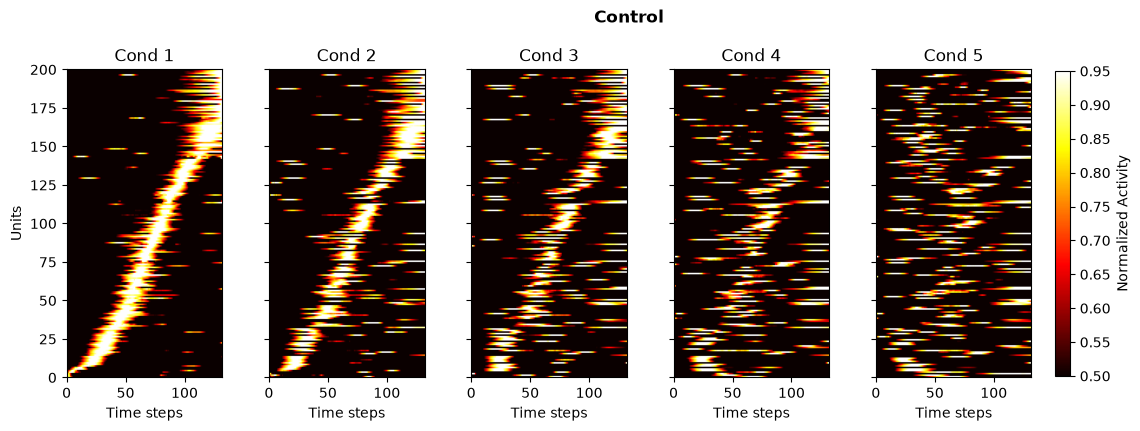

Control      | conditions [0, 1, 2, 3, 4] | averaged activity (5, 200, 132)


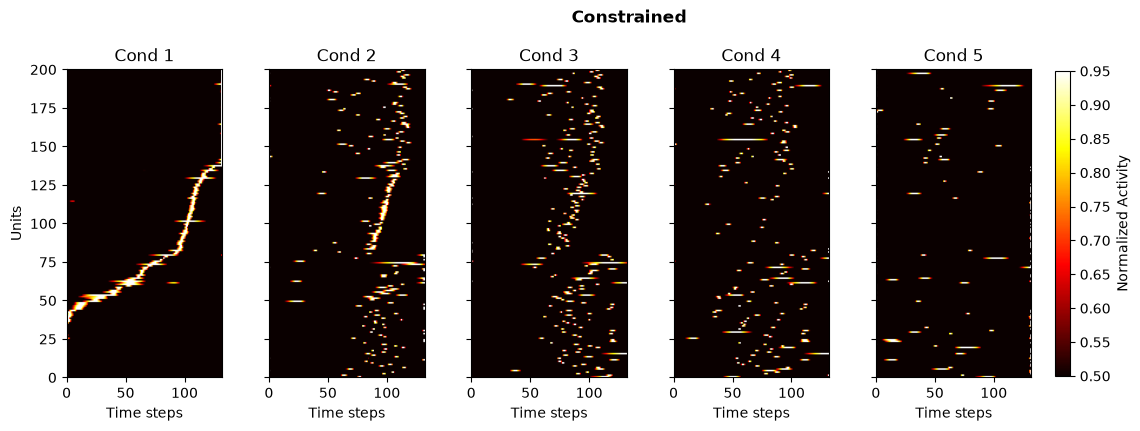

Constrained  | conditions [0, 1, 2, 3, 4] | averaged activity (5, 200, 132)


In [9]:
ACT = {}
vmin, vmax = 0.5, 0.95

for name in MODEL_LABELS:
    fig, ax = plt.subplots(1, NUM_TRAJECTORIES, figsize=(15, 4))
    Labels, ACT[name] = plot_sorted_averaged_activations(ax, LABELS, HIDDEN[name],
                                                         vmin=vmin, vmax=vmax)
    fig.suptitle(name, y=1.03, fontweight="bold")
    plt.show()
    print(f"{name:12s} | conditions {Labels} | averaged activity {ACT[name].shape}")

## **4. RSM matrices & plots**

In [10]:
RSM = {}

for name in MODEL_LABELS:
    RSM[name] = compute_rsm(ACT[name])
    print(f"{name:12s} | RSM {RSM[name].shape}")
    print(np.round(RSM[name], 3), "\n")

Control      | RSM (5, 5)
[[1.    0.852 0.76  0.653 0.525]
 [0.852 1.    0.917 0.777 0.614]
 [0.76  0.917 1.    0.89  0.692]
 [0.653 0.777 0.89  1.    0.823]
 [0.525 0.614 0.692 0.823 1.   ]] 

Constrained  | RSM (5, 5)
[[1.    0.044 0.045 0.036 0.031]
 [0.044 1.    0.034 0.045 0.033]
 [0.045 0.034 1.    0.049 0.035]
 [0.036 0.045 0.049 1.    0.06 ]
 [0.031 0.033 0.035 0.06  1.   ]] 



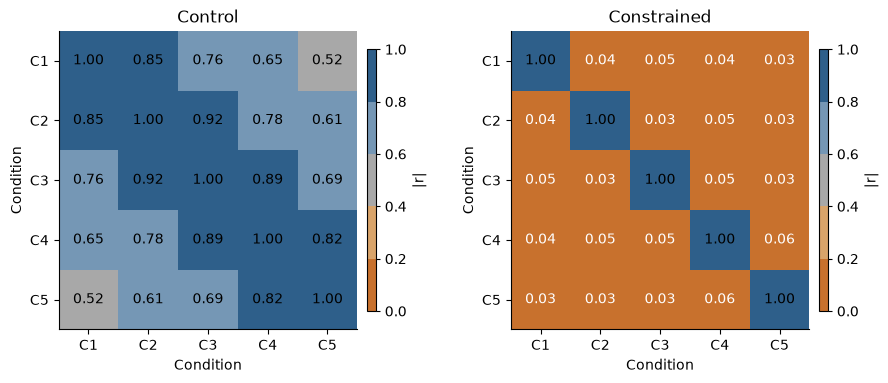

In [11]:
from matplotlib.colors import ListedColormap
COLORS = ["#c8712d", "#d9a46a", "#a8a8a8", "#7597b5", "#2e5f8a"]
PAIR = [COLORS[0], COLORS[-1]]
cmap = ListedColormap(COLORS)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.subplots_adjust(wspace=0.4)

plot_rsm(RSM[MODEL_LABELS[0]], title=MODEL_LABELS[0], ax=axes[0], cbar_label="|r|", cmap= cmap)
plot_rsm(RSM[MODEL_LABELS[1]], title=MODEL_LABELS[1], ax=axes[1], cbar_label="|r|", cmap= cmap)
plt.show()

## **5. Boxplot — Epochs**

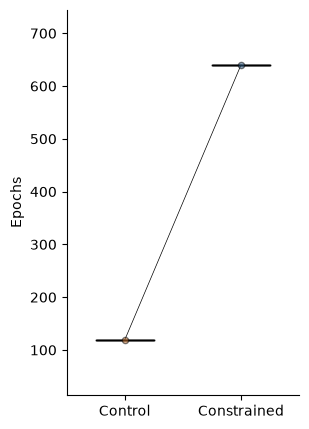

Control     : 119.0 +/- nan
Constrained : 640.0 +/- nan
t = nan, p = nan, n = 1


In [12]:
data = np.array([EPOCHS[MODEL_LABELS[0]], EPOCHS[MODEL_LABELS[1]]], dtype=float)
padding = 0.2 * (data.max() - data.min() + 1e-12)

fig, ax = plt.subplots(figsize=(3, 5))
boxplot_with_lines(ax, data, xlabel=MODEL_LABELS, ylabel="Epochs", colours=PAIR,
                   ymin=data.min() - padding, ymax=data.max() + padding,
                   use_legend=False)

stat = {}
stat["t"], stat["p"] = ttest_rel(data[0], data[1])
plot_siginficance_symbol_paired(ax, data, stat, height=0.1)
plt.show()

print(f"Control     : {data[0].mean():.1f} +/- {data[0].std(ddof=1):.1f}")
print(f"Constrained : {data[1].mean():.1f} +/- {data[1].std(ddof=1):.1f}")
print(f"t = {stat['t']}, p = {stat['p']}, n = {data.shape[1]}")

## **6. Boxplot — Correlation**

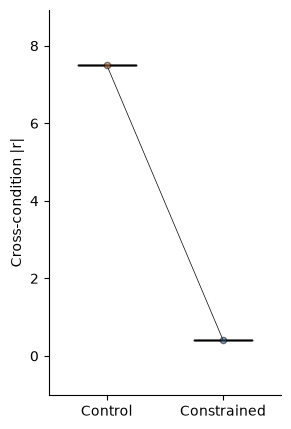

Control     : 7.5042 +/- nan
Constrained : 0.4115 +/- nan
t = nan, p = nan, n = 1


In [13]:
data = np.array([CORRS[MODEL_LABELS[0]], CORRS[MODEL_LABELS[1]]], dtype=float)
padding = 0.2 * (data.max() - data.min() + 1e-12)

fig, ax = plt.subplots(figsize=(3, 5))
boxplot_with_lines(ax, data, xlabel=MODEL_LABELS, ylabel="Cross-condition |r|",
                   colours=PAIR,
                   ymin=data.min() - padding, ymax=data.max() + padding,
                   use_legend=False)

stat = {}
stat["t"], stat["p"] = ttest_rel(data[0], data[1])
plot_siginficance_symbol_paired(ax, data, stat, height=0.1)
plt.show()

print(f"Control     : {data[0].mean():.4f} +/- {data[0].std(ddof=1):.4f}")
print(f"Constrained : {data[1].mean():.4f} +/- {data[1].std(ddof=1):.4f}")
print(f"t = {stat['t']}, p = {stat['p']}, n = {data.shape[1]}")